# LangGraph 长短期记忆概述
**前面课程中的所有实现都只能执行单一任务。一旦图被编译并根据用户的输入运行以后，它虽然可以按照既定的图流程输出结果，但在下一次交互时，这个图将无法记住之前的对话内容**。

<div align=center><img src="./pic/lesson07/1.png" width=80%></div>

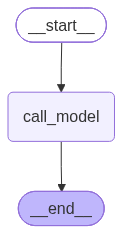

In [2]:
from langchain_openai import ChatOpenAI
import os

llm = ChatOpenAI(
    model="gpt-4o",
    api_key=os.getenv("OPENAI_API_KEY"),
    base_url="https://api.openai.com/v1",
)

from typing_extensions import TypedDict
from typing import Annotated
from langgraph.graph.message import add_messages
from langgraph.graph import StateGraph


class State(TypedDict):
    messages: Annotated[list, add_messages]


def call_model(state: State):
    return {"messages": llm.invoke(state["messages"])}


builder = StateGraph(State)

builder.add_node("call_model", call_model)

builder.set_entry_point("call_model")
builder.set_finish_point("call_model")

# 编译图
simple_graph = builder.compile()

# 可视化
from IPython.display import Image, display

display(Image(simple_graph.get_graph().draw_mermaid_png()))

In [4]:
async for chunk in simple_graph.astream(
    input={"messages": ["你好, 我叫Devin"]}, stream_mode="values"
):
    message = chunk["messages"][-1].pretty_print()

================================ Human Message =================================

你好, 我叫Devin
================================== Ai Message ==================================

你好，Devin！很高兴认识你。有什么我可以帮助你的吗？


In [5]:
async for chunk in simple_graph.astream(
    input={"messages": ["你知道我的名字吗"]}, stream_mode="values"
):
    message = chunk["messages"][-1].pretty_print()

================================ Human Message =================================

你知道我的名字吗
================================== Ai Message ==================================

抱歉，我不知道你的名字。你可以告诉我你的名字或者随便聊聊其他话题。


**在构建图的时候不是通过`State`状态模式中的`add_messages`这个`Reducer`函数维护了一个消息列表吗，看似已经在处理记忆功能，但为何不生效呢?**

In [8]:
import json


def pretty_dump(obj):
    def _default(o):
        if hasattr(o, "model_dump"):
            d = o.model_dump()
            # 如果 ToolMessage.content 是 JSON 字符串，顺便解析成字典方便阅读
            if isinstance(d.get("content"), str) and d["content"].lstrip().startswith(
                ("{", "[")
            ):
                try:
                    d["content"] = json.loads(d["content"])
                except Exception:
                    pass
            return d
        return str(o)

    print(json.dumps(obj, indent=2, ensure_ascii=False, default=_default))

In [13]:
async for chunk in simple_graph.astream(
    input={"messages": ["你好，我叫Devin"]}, stream_mode="values"
):
    print(chunk)
    print(20 * "=" + " pretty_dump " + 20 * "=")
    pretty_dump(chunk)

{'messages': [HumanMessage(content='你好，我叫Devin', additional_kwargs={}, response_metadata={}, id='784fcc1c-1ce8-4bc0-b7e7-9536dda98d07')]}
==================== pretty_dump ====================
{
  "messages": [
    {
      "content": "你好，我叫Devin",
      "additional_kwargs": {},
      "response_metadata": {},
      "type": "human",
      "name": null,
      "id": "784fcc1c-1ce8-4bc0-b7e7-9536dda98d07"
    }
  ]
}
{'messages': [HumanMessage(content='你好，我叫Devin', additional_kwargs={}, response_metadata={}, id='784fcc1c-1ce8-4bc0-b7e7-9536dda98d07'), AIMessage(content='你好，Devin！很高兴认识你。有什么我可以帮助你的吗？', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 18, 'prompt_tokens': 12, 'total_tokens': 30, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_

```json
{
  "messages": [
    {
      "content": "你好，我叫Devin",
      "additional_kwargs": {},
      "response_metadata": {},
      "type": "human",
      "name": null,
      "id": "784fcc1c-1ce8-4bc0-b7e7-9536dda98d07"
    },
    {
      "content": "你好，Devin！很高兴认识你。有什么我可以帮助你的吗？",
      "additional_kwargs": {
        "refusal": null
      },
      "response_metadata": {
        "token_usage": {
          "completion_tokens": 18,
          "prompt_tokens": 12,
          "total_tokens": 30,
          "completion_tokens_details": {
            "accepted_prediction_tokens": 0,
            "audio_tokens": 0,
            "reasoning_tokens": 0,
            "rejected_prediction_tokens": 0,
            "text_tokens": null
          },
          "prompt_tokens_details": {
            "audio_tokens": 0,
            "cache_write_tokens": null,
            "cached_tokens": 0,
            "image_tokens": null,
            "text_tokens": null
          }
        },
        "model_provider": "openai",
        "model_name": "gpt-4o-2024-08-06",
        "system_fingerprint": "fp_7d271e4ea9",
        "id": "chatcmpl-EnQN7a4LQK0vl0LMOMaKnmcocDsKd",
        "service_tier": "default",
        "finish_reason": "stop",
        "logprobs": null
      },
      "type": "ai",
      "name": null,
      "id": "lc_run--01a2090c-9e37-7483-94a2-3db9bd15efff-0",
      "tool_calls": [],
      "invalid_tool_calls": [],
      "usage_metadata": {
        "input_tokens": 12,
        "output_tokens": 18,
        "total_tokens": 30,
        "input_token_details": {
          "audio": 0,
          "cache_read": 0
        },
        "output_token_details": {
          "audio": 0,
          "reasoning": 0
        }
      }
    }
  ]
}
```

其实可以看到, `call_model`到`END`节点之间，在在`Messages`中记录了`HumanMessage(content='你好，我叫Devin', ....），AIMessage(content='你好，Devin！很高兴认识你。有什么我可以帮助你的吗？'`的有效信息

这看起来是合理的。但是当我们发起一轮新的问答的时候：

如果按照能让该图具备上下文记忆能力的话，其维护的`Messages`应该是：
```json
{'messages': [HumanMessage(content='你好，我叫Devin') .....]
    
{'messages': [HumanMessage(content='你好，我叫Devin') , 
              AIMessage(content='你好，Devin！很高兴认识你。有什么我可以帮助你的吗？') .....]

{'messages': [HumanMessage(content='你好，我叫Devin') ,  
              AIMessage(content='你好，Devin！很高兴认识你。有什么我可以帮助你的吗？') , 
              HumanMessage(content='你知道我叫什么吗？')....]
```

In [14]:
async for chunk in simple_graph.astream(
    input={"messages": ["请问你知道我叫什么吗？"]}, stream_mode="values"
):
    print(chunk)
    print(20 * "=" + " pretty_dump " + 20 * "=")
    pretty_dump(chunk)

{'messages': [HumanMessage(content='请问你知道我叫什么吗？', additional_kwargs={}, response_metadata={}, id='30ee7ed6-96c0-4d58-ad00-22b9129bac03')]}
==================== pretty_dump ====================
{
  "messages": [
    {
      "content": "请问你知道我叫什么吗？",
      "additional_kwargs": {},
      "response_metadata": {},
      "type": "human",
      "name": null,
      "id": "30ee7ed6-96c0-4d58-ad00-22b9129bac03"
    }
  ]
}
{'messages': [HumanMessage(content='请问你知道我叫什么吗？', additional_kwargs={}, response_metadata={}, id='30ee7ed6-96c0-4d58-ad00-22b9129bac03'), AIMessage(content='很抱歉，我无法知道你的名字或任何个人信息。', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 13, 'prompt_tokens': 15, 'total_tokens': 28, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_toke

在第二轮提问后，`State`状态中的`messages`字段并未如预期那样更新，这就导致了即使是同一个图连续接收到用户的问题，每一个问题对于它而言都是完全新的，没有任何上下文关联。

所以，**在`LangGraph`框架中，`State`状态模式的设计本质上是用于在单次运行期间维持和传递整个图节点的消息状态。每次运行完成后，状态会重置到初始状态。以此确保每次运行的独立性，防止了不同运行间的数据干扰。但这也意味着图无法保留跨次运行的上下文信息**。

# 1. AI Agent的记忆认知

**记忆是一种允许个体存储、检索并利用信息以理解过去和规划未来的关键认知功能**。像人类一样，通过学习、经验获得的知识可以在需要的时候从大脑中检索出来。

对于`AI Agent`来说，随着其承担越来越复杂、涉及大量用户交互的任务，通过`State`状态的管理，是可以处理从大任务拆分出来的各个子任务间的记录和阶段性成果，这本质上就是一种记忆形式。

无论是运行中的状态信息传递还是跨对话间的信息保存，记忆功能都适用于多种场景，并有多种实现方式。**不同的结构框架对`Memory`的实现和定位都会有所不同，但都会将其所实现的记忆功能分为短期记忆和长期记忆两大类**

**短期记忆的普遍理解是指那些存储在缓存、内存或程序运行过程中的状态信息**。这类信息通常作为整个大模型或`Agent`的短期记忆，在构建过程中通过数据接口进行临时存储，并在任务完成后直接被清除，就像`LangGraph`的`State`状态机制一样。

**长期记忆通常涉及将重要数据通过特定方式持久化保存在某种存储容器中，任何程序都可以在这里提取到内容，且不受时间的影响**，一般这种常规的实现方法是数据库的本地存储。

`LangGraph`框架的设计思路就如下图所示：

> LangGraph Memory Docs：https://langchain-ai.github.io/langgraph/concepts/memory/#what-is-memory

<div align=center><img src="./pic/lesson07/a.png" width=80%></div>

每个`AI Agent`开发框架都会包含记忆模块，但具体应用的方法一定都是不一样的，也势必会产生特有的专业名词来定义这个过程。
`LangGraph` 框架通过`Checkpointer` 和 `Store`分别作为长短期记忆的管理模块，而其整体对这两类记忆的定位则是：

- **短期记忆：允许 Agent 访问图中较早步骤中获取的信息，并且可以可以随时从与用户的单个对话线程中调用。**
- **长期记忆：使 Agent 能够回忆起之前交互中的信息，例如对话中过去的消息，并且可以在对话线程之间共享，在任何时间、任何线程中调用。**

# 2. 短期记忆及Checkpointer

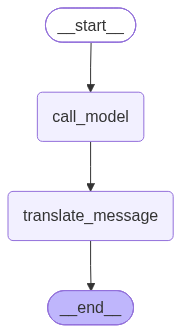

In [12]:
from langchain_openai import ChatOpenAI
import os

llm = ChatOpenAI(
    model="gpt-4o",
    api_key=os.getenv("OPENAI_API_KEY"),
    base_url="https://api.openai.com/v1",
)


from typing_extensions import TypedDict
from typing import Annotated
from langgraph.graph.message import add_messages


class State(TypedDict):
    messages: Annotated[list, add_messages]


def call_model(state: State):
    return {"messages": [llm.invoke(state["messages"])]}


from langchain_core.messages import SystemMessage, HumanMessage


def translate_message(state: State):
    system_prompt = """
    Please translate the received text in any language into English as output
    """
    human_message = state["messages"][-1]
    message = [SystemMessage(system_prompt)] + [HumanMessage(human_message.content)]
    return {"messages": [llm.invoke(message)]}


from langgraph.graph import StateGraph

builder = StateGraph(State)

builder.add_node("call_model", call_model)
builder.add_node("translate_message", translate_message)

builder.set_entry_point("call_model")
builder.add_edge("call_model", "translate_message")
builder.set_finish_point("translate_message")

simple_graph = builder.compile()

# 可视化
from IPython.display import Image, display

display(Image(simple_graph.get_graph().draw_mermaid_png()))

In [ ]:
async for chunk in simple_graph.astream(
    input={"messages": ["你好, 我是Devin"]}, stream_mode="debug"
):
    payload = chunk["payload"]
    print(f"Task ID: {payload['id']}")

    chunk_type = chunk["type"]
    if chunk_type == "task":
        for message in payload["input"]["messages"]:
            print(f"*task message id*: {message.id}, \n*content*: {message.content}")
    elif chunk_type == "task_result":
        for message in payload["result"]["messages"]:
            print(
                f"*task result message id*: {message.id}, \n*content*: {message.content}"
            )

    print(40 * "=")

Task ID: 366b6e6b-9c5e-5f42-0da5-ea202c59660b
task message id: f1637bb7-ffbb-411e-a9b9-249c650fdadb, content: 你好, 我是Devin
Task ID: 366b6e6b-9c5e-5f42-0da5-ea202c59660b
task result message id: lc_run--01a20e50-0341-79d3-9a18-6f83b783fcd1-0, content: 你好，Devin！很高兴见到你。有什么我可以帮助你的吗？
Task ID: 8efded12-a59c-c8ca-59bc-cc0339f17c93
task message id: f1637bb7-ffbb-411e-a9b9-249c650fdadb, content: 你好, 我是Devin
task message id: lc_run--01a20e50-0341-79d3-9a18-6f83b783fcd1-0, content: 你好，Devin！很高兴见到你。有什么我可以帮助你的吗？
Task ID: 8efded12-a59c-c8ca-59bc-cc0339f17c93
task result message id: lc_run--01a20e50-0c2e-7522-9ca4-bc5bfef28f78-0, content: Hello, Devin! Nice to meet you. Is there anything I can help you with?
